<a href="https://colab.research.google.com/github/Haileyngo/Stats-for-Data-Science/blob/main/Stats_HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Four ways of counting
Hailey Ngo - Oct 8, 2026


Imagine you have a set of N possible objects (cards, lottery numbers, people, user IDs, etc.) and you randomly
draw M of them. The size of the sample space (the number of possible outcomes) depends on two key
questions:
1. Does the order of the draws matter?
2. Are we drawing with or without replacement?


Therefore, there are four different scenarios for counting:
1. Ordered, With Replacement
2. Ordered, Without Replacement
3. Unordered, Without Replacement
4. Unordered, With Replacement

**Part 1: Create a plot summarizing these four different scenarios for N = 50.**

● The x-axis should be M, ranging from 0 to 50 (inclusive).

● Your plot should have four distinct lines, one for each case

● Make sure the plot is readable! This means it must have a title, axis labels, a legend identifying the four curves, and it all should be legible on a slide.

A note of caution: these numbers grow incredibly large, quickly. You will need to be thoughtful about how you
create your plot. For example, consider using a logarithmic scale for the y-axis to make the results viewabl

saved


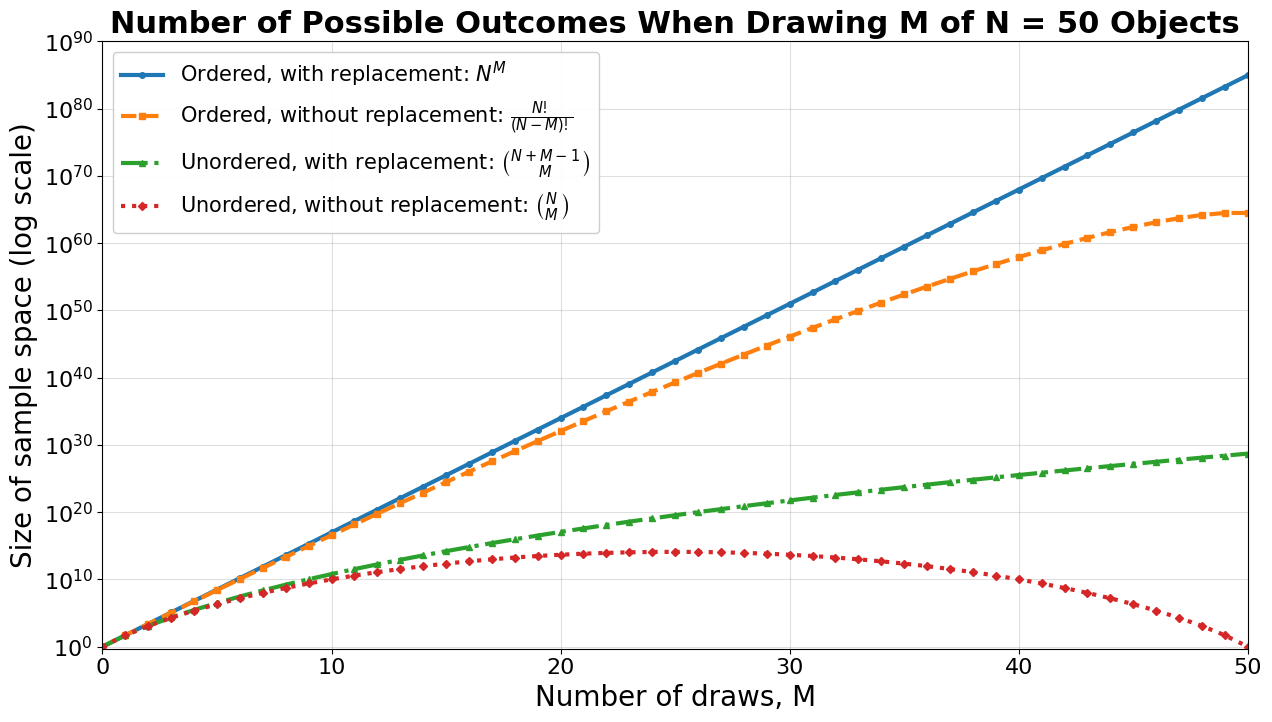

In [ ]:
"""Sample-space size for drawing M of N = 50 objects, under four counting scenarios."""
from math import comb, perm

import matplotlib.pyplot as plt

N = 50
M = list(range(0, N + 1))

# Exact integer counts (Python ints never overflow); converted to float only for plotting.
# The largest value, 50^50 ~ 8.9e84, fits comfortably in a float64.
ordered_with    = [N ** m             for m in M]   # N^M
ordered_without = [perm(N, m)         for m in M]   # N! / (N-M)!
unordered_without = [comb(N, m)       for m in M]   # C(N, M)
unordered_with  = [comb(N + m - 1, m) for m in M]   # C(N+M-1, M)  (stars and bars)

plt.rcParams.update({"font.size": 16})
fig, ax = plt.subplots(figsize=(13, 7.5))

ax.plot(M, [float(v) for v in ordered_with],      lw=3,   ls="-",  marker="o", ms=4,
        label=r"Ordered, with replacement: $N^M$")
ax.plot(M, [float(v) for v in ordered_without],   lw=3,   ls="--", marker="s", ms=4,
        label=r"Ordered, without replacement: $\frac{N!}{(N-M)!}$")
ax.plot(M, [float(v) for v in unordered_with],    lw=3,   ls="-.", marker="^", ms=5,
        label=r"Unordered, with replacement: $\binom{N+M-1}{M}$")
ax.plot(M, [float(v) for v in unordered_without], lw=3,   ls=":",  marker="D", ms=4,
        label=r"Unordered, without replacement: $\binom{N}{M}$")

ax.set_yscale("log")
ax.set_xlim(0, N)
ax.set_ylim(0.5, 1e90)
ax.set_yticks([10.0**k for k in range(0, 91, 10)])
ax.set_xlabel("Number of draws, M", fontsize=20)
ax.set_ylabel("Size of sample space (log scale)", fontsize=20)
ax.set_title(f"Number of Possible Outcomes When Drawing M of N = {N} Objects",
             fontsize=22, fontweight="bold")
ax.grid(True, which="major", alpha=0.4)
ax.legend(loc="upper left", fontsize=15, framealpha=0.95)
ax.tick_params(labelsize=16)

fig.tight_layout()
fig.savefig("sample_space_N50.png", dpi=200)
print("saved")

**Part 2: Analyze Your Plot
Answer the following questions. Your answers should be at a technical level appropriate for explaining to a classmate.**

**1. At what value of M is the Unordered Without Replacement curve largest, and why?**

To solve this problem, we will use Binomial distribution since:
- Have a fixed number of indenpendent trials
- Model the number of successes
- Each trial only has 2 outcomes (picked and not picked)

The probability of getting exactly M successes in 50 trials is:
$$ P(X = M) = \binom{50}{M}(0.5)^{M}(0.5)^{50-M} = \binom{50}{M}0.5^{50}$$

Since $\binom{50}{M} = \binom{50}{50-M}$ for all $0 \le M \le 50$, the curve is a mirror image when $M=25$.

To find the max M, we will find M when $$\frac{\binom{N}{M+1}}{\binom{N}{M}} > 1$$

\begin{align*}
\frac{\binom{N}{M+1}}{\binom{N}{M}}
&= \frac{N!}{(M+1)!\,(N-M-1)!} \cdot \frac{M!\,(N-M)!}{N!} \\
&= \frac{M!}{(M+1)!} \cdot \frac{(N-M)!}{(N-M-1)!} \\
&= \frac{1}{M+1} \cdot (N-M)
 = \frac{N-M}{M+1}.
\end{align*}

When

$$\frac{N-M}{M+1} > 1 \iff N - M > M + 1 \iff M < \frac{N-1}{2} = 24.5$$

Thus, for $M \le 24$, the ratio is greater than 1, so the curve is rising. When $M \ge 25$, the ratio is smaller than 1, so the curve is falling. Since $M$ must be a discrete integer, the curve reaches its peak at $M = 25$.

The curve Unordered Without Replacement will achieve its peak at $M = \frac{N}{2} = \frac{50}{2} = 25$, where the curve = $\binom{50}{25} \approx 1.26 \times 10^{14}$.


**2. One of the four curves has a qualitatively different shape than the other three. Which curve is it, and what causes this difference?**
The curve **Unordered Without Replacement** $\binom{N}{M}$ is the only curve that is not monotonic (it increases, reaches a peak, and then decreases). As shown above, this is because the denominator of the combination formula grows faster than the numerator once $M > N/2$.

To validate that other three curves are monotonic, we will use the same method step ratio as in question 1:

- **Ordered With Replacement ($N^M$):**
  $$\frac{N^{M+1}}{N^M} = N = 50$$
  Since the ratio is constant at 50 (which is $> 1$), this curve grows exponentially and monotonically.

- **Ordered Without Replacement $P(N, M) = \frac{N!}{(N-M)!}$:**


  $$\frac{P(N, M+1)}{P(N, M)} = \frac{N!}{(N-M-1)!} \cdot \frac{(N-M)!}{N!} = N - M$$


  For $0 \le M < N$ (or $0 \le M \le 49$), the ratio $N - M \ge 1$. Thus, the terms are strictly non-decreasing up to $M = 50$.

- **Unordered With Replacement $\binom{N+M-1}{M}$:**


  The step ratio is:
  $$\frac{\binom{N+M}{M+1}}{\binom{N+M-1}{M}} = \frac{N+M}{M+1}$$


  Since $N = 50$, we have $\frac{50+M}{M+1} > 1$ for all $M \ge 0$. Therefore, this curve always strictly increases.


**3. What happens to the Ordered Without Replacement curve when M > N? Does your plot reflect this? Why or why not?**



When $M > N$, we are attempting to draw more items than are available in the set without replacing them. This is physically impossible, meaning the number of outcomes becomes exactly **0**. This would also violdate Axiom Non-negativity, stating that the probability of M must always be larger than 0.

Our plot does not reflect this because the range of $M$ on our x-axis only goes from $0$ to $N$ ($50$ inclusive). If we were to extend $M > 50$, the value would drop to $0$. On a logarithmic y-axis scale, $0$ cannot be plotted because $\log(0) = -\infty$.


**4. A classmate claims that Ordered With Replacement is always the strictly largest curve. Is this true for all integer values of M between 0 and 50? Identify any specific values of M where the claim fails, and explain mathematically why it fails at those points.**

No, the classmate's claim is false at two specific boundary points:

1. **At $M = 0$:**
   - Ordered With Replacement: $50^0 = 1$
   - Ordered Without Replacement: $P(50, 0) = 1$
   - Unordered With Replacement: $\binom{50-1}{0} = 1$
   - Unordered Without Replacement: $\binom{50}{0} = 1$

All four scenarios yield exactly $1$ outcome. Thus, Ordered With Replacement is not *strictly* larger.

2. **At $M = 1$:**
   - Ordered With Replacement: $50^1 = 50$
   - Ordered Without Replacement: $P(50, 1) = 50$
   - Unordered With Replacement: $\binom{50}{1} = 50$
   - Unordered Without Replacement: $\binom{50}{1} = 50$
   
All four scenarios yield exactly $50$ outcomes. Thus, Ordered With Replacement is not *strictly* larger.

For all $M \ge 2$, however, Ordered With Replacement is indeed strictly larger than the other three curves because drawing with replacement and considering order always yields the maximum possible freedom of choices ($N^M$).


**Part 3: Classification**


For each of the following scenarios, identify which of the four counting methods applies and compute the size of
the sample space.


**1. A bank generates 6-digit PINs for customers, where each digit is drawn from 0–9 and digits can repeat.**

Method: Ordered Without Replacement since the order matters and digits can repeat.

Sample Space: $S = 10^6$.



**2. A competition selects 3 finalists from 20 participants and awards them distinct prizes: $10,000 for first place,
$5,000 for second, and $1,000 for third.**

Method: Ordered without Replacement since the order of choosing first, second, and third matters, and no one person can win two prizes.

Sample Space: $S = 20 \times 19 \times 18 = \frac{20!}{3!} = 6840$



**3. A data scientist selects 5 features from 20 candidate variables to include in a logistic regression model. The
model doesn't care about the order the features were chosen.**

Method: Unordered Without Replacement since the model doesn't depend on order, and no same variable can be included twice in the model.

Sample Space: $S = \binom{20}{5} = 15504$



**4. A coffee shop offers 8 syrup flavors. A customer orders a drink with 3 pumps of syrup, where each pump can
be any flavor and the order of pumps doesn't affect the final drink.**

Method: Unordered With Replacement since the order of pumps doesn't change the drink, and the flavors can repeat.

Sample Space: $S = \binom{8+3-1}{3}= \binom{10}{3} = 120$



**5. A company runs a multivariate test with 3 arms. Each of 500 users is independently and randomly assigned to
exactly one arms. How many distinct ways can the 500 users be assigned across the 3 arms?**

Method: Ordered With Replacement since each user is unique and there is no limit on number of assigned users per arm, and many users can land in the same arm.  

Sample Space: $S = \binom{500+3-1}{500}= \binom{502}{500} = 125751$.



**6. A hiring committee of 4 is chosen from 30 senior employees. All committee members have equal roles.**

Method: Unordered Without Replacement since all committee members have equal roles and one person cannot hold two seats.

Sample Space: $S = \binom{30}{4} = 27405$


**Part 4: AI Reflection**

Include the prompts you used when working with AI tools on this assignment (not the full AI responses — just
your prompts). Write a short paragraph (3–5 sentences) addressing: Did the AI produce any errors or
oversimplifications? How did you verify the AI's output? What did you have to correct or add yourself?

At first, I pasted the question in and only requesting answers to graduate statistics level. With this prompt, AI was at first explaining to me how to solve the questions using knowledge that I am unaware of, or at times it would oversimplify using over-generalized examples that only cover 1 specific case. I had to provide the lecture slides and request it to use relevant concepts introduced in the lecture slides to help me answer the questions. For all assignments, I came up with a structure of the answer first, without going into too much details, and then use that to compare against AI's results. Gradually, I have to add more context on the audience, the allowed methods, and expected formats. This is the final prompt that I used:

*I'm answering [Part X, Question Y] of a homework for a graduate data-science statistics course. The question text is: [paste the question].

Audience: a classmate who has seen lecture slides. Don't go beyond that unless you flag it as optional.
Allowed methods: prefer the attached lecture slides. If you use anything not in them, say so and justify it from first principles.
Rigor: prove claims from definitions. Don't introduce a model or analogy unless you state explicitly how it relates to the original problem.
Verify: check any numbers by computation and tell me what you checked.
Format: final answer ready to paste into a Colab markdown cell, with LaTeX format, under [N] words.*